<a href="https://colab.research.google.com/github/RafayRizwan023/Deep_Learning_Labs_Raf023/blob/main/Lab_07_Fine_Tuning_model_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
import copy
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import models, datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


Load and preprocess the Oxford Pet dataset

In [20]:
IM_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2  # If a notebook environment has worker issues, change this to 0.
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IM_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
val_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IM_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_data = datasets.OxfordIIITPet(
    root="data", split="trainval", transform=train_tf, download=True
)
val_data = datasets.OxfordIIITPet(
    root="data", split="test", transform=val_tf, download=True
)

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_data, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

class_names = train_data.classes
num_classes = len(class_names)
print("Classes:", num_classes)
print("Training images:", len(train_data), "| Test images:", len(val_data))

Classes: 37
Training images: 3680 | Test images: 3669


Display sample images

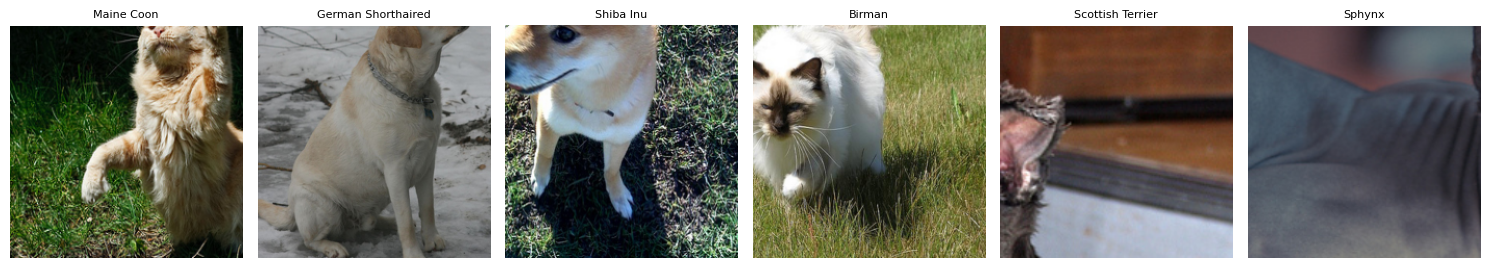

In [21]:
def show_samples(loader, n=6):
    images, labels = next(iter(loader))
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    plt.figure(figsize=(15, 3))
    for i in range(min(n, len(images))):
        image = (images[i].cpu() * std + mean).permute(1, 2, 0).clamp(0, 1)
        plt.subplot(1, n, i + 1)
        plt.imshow(image)
        plt.title(class_names[labels[i]], fontsize=8)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_samples(train_loader)

# **The main Models**

In [22]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def build_resnet50_feature_extractor(num_classes):
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    for p in model.parameters():
        p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model.to(device)


def build_vgg16_finetune(num_classes, unfreeze_last_block=True):
    model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    for p in model.parameters():
        p.requires_grad = False

    # Replace the final classification layer for the 37 pet classes.
    in_features = model.classifier[6].in_features
    model.classifier[6] = nn.Linear(in_features, num_classes)

    # Fine-tune the last convolutional block (indices 24 onward).
    if unfreeze_last_block:
        for p in model.features[24:].parameters():
            p.requires_grad = True
    # The newly added classifier must always be trainable.
    for p in model.classifier[6].parameters():
        p.requires_grad = True

    return model.to(device)


def build_model(model_name, num_classes):
    if model_name == "custom_cnn":
        return CustomCNN(num_classes).to(device)
    if model_name == "resnet50_feature":
        return build_resnet50_feature_extractor(num_classes)
    if model_name == "vgg16_finetune":
        return build_vgg16_finetune(num_classes, unfreeze_last_block=True)
    raise ValueError(f"Unknown model: {model_name}")


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

for name in ["custom_cnn", "resnet50_feature", "vgg16_finetune"]:
    model = build_model(name, num_classes)
    total, trainable = count_parameters(model)
    print(f"{name:20s} total={total/1e6:.2f}M, trainable={trainable/1e6:.2f}M")
    del model

custom_cnn           total=0.43M, trainable=0.43M
resnet50_feature     total=23.58M, trainable=0.08M
vgg16_finetune       total=134.41M, trainable=7.23M


In [23]:
def train_model(model, epochs=10, lr=1e-3, weight_decay=1e-4,
                patience=3, min_delta=1e-4, model_name="model"):
    criterion = nn.CrossEntropyLoss()

    # Default optimizer uses only trainable parameters.
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(
        trainable_params, lr=lr, weight_decay=weight_decay
    )

    history = {
        "train_loss": [], "train_acc": [],
        "val_loss": [], "val_acc": []
    }
    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss, running_correct, running_total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            running_correct += (outputs.argmax(1) == labels).sum().item()
            running_total += labels.size(0)

        train_loss = running_loss / running_total
        train_acc = running_correct / running_total

        model.eval()
        val_loss_sum, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss_sum += loss.item() * labels.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_sum / val_total
        val_acc = val_correct / val_total
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"{model_name} | epoch {epoch+1:02d}/{epochs} "
            f"| train loss {train_loss:.4f} acc {train_acc:.3f} "
            f"| val loss {val_loss:.4f} acc {val_acc:.3f}"
        )

        if val_loss < best_val_loss - min_delta:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if patience is not None and epochs_without_improvement >= patience:
                print(f"Early stopping: validation loss did not improve for {patience} epochs.")
                break

    model.load_state_dict(best_weights)
    elapsed = time.time() - start_time
    best_epoch = int(np.argmin(history["val_loss"])) + 1
    result = {
        "best_val_loss": min(history["val_loss"]),
        "best_val_acc": max(history["val_acc"]),
        "best_epoch": best_epoch,
        "time_sec": elapsed,
        "history": history,
    }
    return model, result

In [6]:
EPOCHS = 15
PATIENCE = 3

configs = {
    "Custom CNN": {
        "model_name": "custom_cnn", "lr": 1e-3, "weight_decay": 1e-4
    },
    "ResNet50 feature extraction": {
        "model_name": "resnet50_feature", "lr": 1e-3, "weight_decay": 1e-4
    },
    "VGG16 fine-tuning": {
        "model_name": "vgg16_finetune", "lr": 1e-4, "weight_decay": 1e-4
    },
}

models_trained, results = {}, {}
for label, cfg in configs.items():
    print("\n" + "=" * 70)
    print("Training:", label)
    model = build_model(cfg["model_name"], num_classes)
    start = time.time()
    model, result = train_model(
        model, epochs=EPOCHS, lr=cfg["lr"],
        weight_decay=cfg["weight_decay"], patience=PATIENCE,
        model_name=label
    )
    result["time_sec"] = time.time() - start
    result["total_params"], result["trainable_params"] = count_parameters(model)
    models_trained[label] = model
    results[label] = result
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Training: Custom CNN
Custom CNN | epoch 01/15 | train loss 3.5568 acc 0.048 | val loss 3.4685 acc 0.071
Custom CNN | epoch 02/15 | train loss 3.4476 acc 0.077 | val loss 3.4470 acc 0.072
Custom CNN | epoch 03/15 | train loss 3.4064 acc 0.076 | val loss 3.4038 acc 0.080
Custom CNN | epoch 04/15 | train loss 3.3617 acc 0.092 | val loss 3.3321 acc 0.088
Custom CNN | epoch 05/15 | train loss 3.3166 acc 0.097 | val loss 3.3394 acc 0.095
Custom CNN | epoch 06/15 | train loss 3.2657 acc 0.107 | val loss 3.2504 acc 0.114
Custom CNN | epoch 07/15 | train loss 3.2078 acc 0.115 | val loss 3.2719 acc 0.109
Custom CNN | epoch 08/15 | train loss 3.1775 acc 0.125 | val loss 3.2522 acc 0.110
Custom CNN | epoch 09/15 | train loss 3.1261 acc 0.137 | val loss 3.2944 acc 0.114
Early stopping: validation loss did not improve for 3 epochs.

Training: ResNet50 feature extraction
ResNet50 feature extraction | epoch 01/15 | train loss 2.1985 acc 0.580 | val loss 1.2223 acc 0.844
ResNet50 feature extraction | 

In [7]:
summary_rows = []
for name, r in results.items():
    summary_rows.append({
        "Model": name,
        "Best validation accuracy": r["best_val_acc"],
        "Best validation loss": r["best_val_loss"],
        "Best epoch": r["best_epoch"],
        "Training time (sec)": r["time_sec"],
        "Total parameters (M)": r["total_params"] / 1e6,
        "Trainable parameters (M)": r["trainable_params"] / 1e6,
    })
summary = pd.DataFrame(summary_rows).sort_values(
    "Best validation accuracy", ascending=False
)
display(summary.round(4))

,Model,Best validation accuracy,Best validation loss,Best epoch,Training time (sec),Total parameters (M),Trainable parameters (M)
1,ResNet50 feature extraction,0.9141,0.2794,14,567.8162,23.5838,0.0758
2,VGG16 fine-tuning,0.9114,0.2992,9,554.3277,134.4121,7.2310
0,Custom CNN,0.1139,3.2504,6,309.5117,0.4270,0.4270


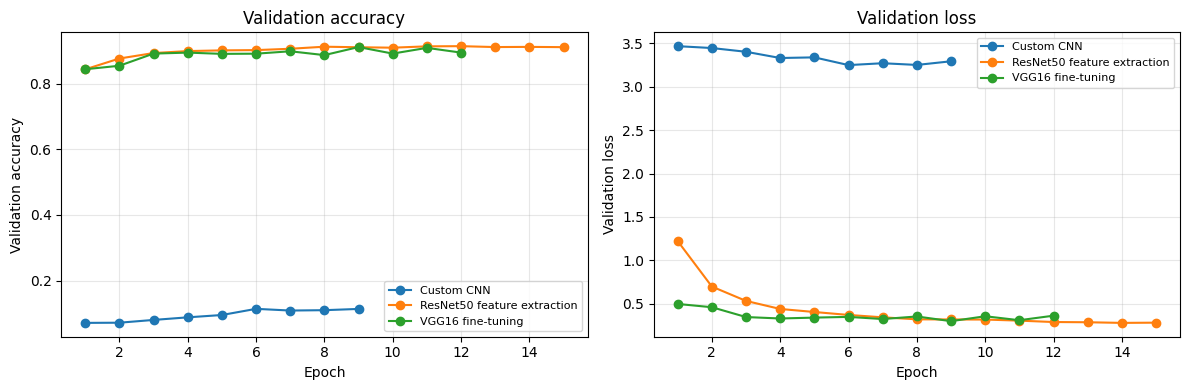

In [8]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
for name, r in results.items():
    h = r["history"]
    plt.plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Validation accuracy")
plt.grid(alpha=0.3)
plt.legend(fontsize=8)

plt.subplot(1, 2, 2)
for name, r in results.items():
    h = r["history"]
    plt.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], marker="o", label=name)
plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Validation loss")
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [9]:
# Experiment A: smaller learning rate for VGG16 fine-tuning
vgg_lr_low = build_vgg16_finetune(num_classes, unfreeze_last_block=True)
vgg_lr_low, vgg_lr_low_result = train_model(
    vgg_lr_low,
    epochs=15,
    lr=1e-5,
    weight_decay=1e-4,
    patience=4,
    model_name="VGG16 fine-tune LR=1e-5"
)
print({
    "best_val_acc": round(vgg_lr_low_result["best_val_acc"], 4),
    "best_val_loss": round(vgg_lr_low_result["best_val_loss"], 4),
    "best_epoch": vgg_lr_low_result["best_epoch"],
})

VGG16 fine-tune LR=1e-5 | epoch 01/15 | train loss 3.5711 acc 0.050 | val loss 3.2862 acc 0.194
VGG16 fine-tune LR=1e-5 | epoch 02/15 | train loss 2.9832 acc 0.181 | val loss 1.8306 acc 0.564
VGG16 fine-tune LR=1e-5 | epoch 03/15 | train loss 2.1424 acc 0.373 | val loss 0.9164 acc 0.775
VGG16 fine-tune LR=1e-5 | epoch 04/15 | train loss 1.5868 acc 0.506 | val loss 0.6348 acc 0.832
VGG16 fine-tune LR=1e-5 | epoch 05/15 | train loss 1.3373 acc 0.583 | val loss 0.5047 acc 0.854
VGG16 fine-tune LR=1e-5 | epoch 06/15 | train loss 1.2141 acc 0.624 | val loss 0.4539 acc 0.857
VGG16 fine-tune LR=1e-5 | epoch 07/15 | train loss 1.0572 acc 0.676 | val loss 0.3996 acc 0.878
VGG16 fine-tune LR=1e-5 | epoch 08/15 | train loss 1.0024 acc 0.689 | val loss 0.3903 acc 0.877
VGG16 fine-tune LR=1e-5 | epoch 09/15 | train loss 0.9530 acc 0.702 | val loss 0.3666 acc 0.887
VGG16 fine-tune LR=1e-5 | epoch 10/15 | train loss 0.9217 acc 0.707 | val loss 0.3530 acc 0.889
VGG16 fine-tune LR=1e-5 | epoch 11/15 | 

# **Improving the fine-tuning results**

So far we have three models: the custom CNN (about 17%), ResNet50 feature extraction (about 91.7%) and VGG16 fine-tuning (about 90.9%). The VGG16 fine-tuning run is the one the lab wants us to improve, so that's what I'll work on from here.

Looking at the curves from the first run, I noticed a few things. The validation loss for VGG16 bounces around after epoch 9 (0.29 -> 0.35) while training accuracy keeps going up, so it's starting to overfit a bit and the learning rate might be too high for the unfrozen conv layers. With LR = 1e-5 (Experiment A) the curve is much smoother, but it was **still improving at epoch 15**, so that run just needed more epochs. Also, only the last conv block was unfrozen, so there might be room to gain by unfreezing more.

I'll try to change one thing at a time where I can. Experiment A (already done above) lowers the learning rate from 1e-4 to 1e-5. In Experiment B I use a different learning rate for the pretrained layers and the new head, add a cosine schedule and train for more epochs, which covers the learning rate and number of epochs hints. Experiment C is the same as B but also unfreezes block 4, to see if unfreezing more layers helps. Experiment D is the same as B but also unfreezes the fully connected layers of the classifier, which covers the "different layers" hint. Experiment E is the same as B but with milder crops, color jitter, rotation and label smoothing, to cover preprocessing and preventing overfitting. Finally, Experiment F does VGG16 feature extraction and ResNet50 fine-tuning, which covers the last two tasks and completes the 2x2 comparison.

Early stopping is already built into `train_model` (patience on validation loss), and I keep it in the new training function too.

### Helper functions for the new experiments

I didn't want to edit the original train_model, so I have wrote a second version. The differences are:

1. it takes parameter groups, so the pretrained layers and the new layer can get different learning rates
2. optional cosine learning rate schedule
3. optional label smoothing (only used for the training loss, validation loss stays plain cross entropy so the numbers are comparable with the earlier runs)
4. mixed precision on GPU, just to make the runs faster on the T4

In [10]:
def build_vgg16(num_classes, unfreeze_from=None, unfreeze_fc=False):
    """VGG16 with a new last layer.
    unfreeze_from: index in model.features to start unfreezing (24 = last conv block,
                   17 = last two conv blocks). None = feature extraction only.
    unfreeze_fc:   also unfreeze the two big fully connected layers (classifier[0] and [3]).
    Returns the model and two lists of params: backbone (pretrained) and head (new layer).
    """
    model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
    for p in model.parameters():
        p.requires_grad = False

    model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)
    head = list(model.classifier[6].parameters())   # new layer, requires_grad is True by default

    backbone = []
    if unfreeze_from is not None:
        for p in model.features[unfreeze_from:].parameters():
            p.requires_grad = True
            backbone.append(p)
    if unfreeze_fc:
        for idx in (0, 3):
            for p in model.classifier[idx].parameters():
                p.requires_grad = True
                backbone.append(p)
    return model.to(device), backbone, head


def build_resnet50(num_classes, unfreeze=()):
    """ResNet50 with a new fc layer. unfreeze is a tuple of block names, e.g. ("layer4",)."""
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    for p in model.parameters():
        p.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, num_classes)
    head = list(model.fc.parameters())

    backbone = []
    for block in unfreeze:
        for p in getattr(model, block).parameters():
            p.requires_grad = True
            backbone.append(p)
    return model.to(device), backbone, head


def train_model_v2(model, backbone, head, backbone_lr=1e-5, head_lr=1e-3,
                   epochs=15, weight_decay=1e-4, patience=4, min_delta=1e-4,
                   label_smoothing=0.0, cosine=True, loader=None, model_name="model"):
    loader = loader if loader is not None else train_loader
    train_criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    eval_criterion = nn.CrossEntropyLoss()

    groups = [{"params": head, "lr": head_lr}]
    if len(backbone) > 0:
        groups.append({"params": backbone, "lr": backbone_lr})
    optimizer = torch.optim.Adam(groups, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs) if cosine else None

    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    bad_epochs = 0
    start = time.time()

    for epoch in range(epochs):
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                outputs = model(images)
                loss = train_criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            loss_sum += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss, train_acc = loss_sum / total, correct / total
        if scheduler is not None:
            scheduler.step()

        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                with torch.autocast(device_type=device.type, enabled=use_amp):
                    outputs = model(images)
                    loss = eval_criterion(outputs.float(), labels)
                v_loss += loss.item() * labels.size(0)
                v_correct += (outputs.argmax(1) == labels).sum().item()
                v_total += labels.size(0)
        val_loss, val_acc = v_loss / v_total, v_correct / v_total

        for k, v in zip(history, (train_loss, train_acc, val_loss, val_acc)):
            history[k].append(v)
        print(f"{model_name} | epoch {epoch+1:02d}/{epochs} "
              f"| train loss {train_loss:.4f} acc {train_acc:.3f} "
              f"| val loss {val_loss:.4f} acc {val_acc:.3f}")

        if val_loss < best_val_loss - min_delta:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
            if patience is not None and bad_epochs >= patience:
                print(f"Early stopping: no improvement in val loss for {patience} epochs.")
                break

    model.load_state_dict(best_weights)
    total_p, trainable_p = count_parameters(model)
    best_epoch = int(np.argmin(history["val_loss"])) + 1
    return model, {
        "best_val_loss": min(history["val_loss"]),
        # accuracy at the epoch with the best val loss (that's the checkpoint we actually keep)
        "best_val_acc": history["val_acc"][best_epoch - 1],
        "best_epoch": best_epoch,
        "time_sec": time.time() - start,
        "total_params": total_p,
        "trainable_params": trainable_p,
        "history": history,
    }


def run_experiment(label, build_fn, **train_kwargs):
    print("\n" + "=" * 70)
    print("Training:", label)
    model, backbone, head = build_fn()
    model, result = train_model_v2(model, backbone, head, model_name=label, **train_kwargs)
    results[label] = result
    print({"best_val_acc": round(result["best_val_acc"], 4),
           "best_val_loss": round(result["best_val_loss"], 4),
           "best_epoch": result["best_epoch"]})
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

One thing to keep in mind: in the original ain_model the best val acc is the highest accuracy over all epochs, but in the new function I report the accuracy at the epoch with the lowest validation loss. That is the checkpoint that actually gets kept, so I think it is the fairer number. It can be a little lower than the max.

In [11]:
# put Experiment A (run above) into the results dict so it is in the final comparison
vgg_lr_low_result["total_params"], vgg_lr_low_result["trainable_params"] = count_parameters(vgg_lr_low)
results["Exp A: VGG16 FT, LR=1e-5"] = vgg_lr_low_result

## trial 2nd: separate learning rates + cosine schedule

The first run used one learning rate (1e-4) for everything, and Experiment A showed that 1e-5 is stable but too slow. The new last layer is randomly initialised so it needs a big learning rate, but the pretrained conv layers already know useful features and only need small nudges. So I'll use **1e-3 for the new layer and 1e-5 for the unfrozen conv block**, with a cosine decay so the LR gets small towards the end, and a few more epochs (20).

In [12]:
run_experiment(
    "Exp B: VGG16 FT, split LR + cosine",
    lambda: build_vgg16(num_classes, unfreeze_from=24),
    backbone_lr=1e-5, head_lr=1e-3, epochs=20, patience=4, cosine=True
)


Training: Exp B: VGG16 FT, split LR + cosine
Exp B: VGG16 FT, split LR + cosine | epoch 01/20 | train loss 1.0367 acc 0.696 | val loss 0.3142 acc 0.890
Exp B: VGG16 FT, split LR + cosine | epoch 02/20 | train loss 0.5733 acc 0.811 | val loss 0.3069 acc 0.893
Exp B: VGG16 FT, split LR + cosine | epoch 03/20 | train loss 0.4965 acc 0.839 | val loss 0.3110 acc 0.892
Exp B: VGG16 FT, split LR + cosine | epoch 04/20 | train loss 0.4744 acc 0.843 | val loss 0.2927 acc 0.902
Exp B: VGG16 FT, split LR + cosine | epoch 05/20 | train loss 0.4527 acc 0.848 | val loss 0.2765 acc 0.909
Exp B: VGG16 FT, split LR + cosine | epoch 06/20 | train loss 0.4393 acc 0.855 | val loss 0.2914 acc 0.901
Exp B: VGG16 FT, split LR + cosine | epoch 07/20 | train loss 0.4186 acc 0.865 | val loss 0.2678 acc 0.910
Exp B: VGG16 FT, split LR + cosine | epoch 08/20 | train loss 0.3838 acc 0.868 | val loss 0.2654 acc 0.908
Exp B: VGG16 FT, split LR + cosine | epoch 09/20 | train loss 0.3537 acc 0.887 | val loss 0.2870 a

{'best_val_loss': 0.26357744551692985,
 'best_val_acc': 0.9116925592804579,
 'best_epoch': 12,
 'time_sec': 595.4980421066284,
 'total_params': 134412133,
 'trainable_params': 7231013,
 'history': {'train_loss': [1.036688306538955,
   0.5733103857092235,
   0.49649798468403195,
   0.4744061335273411,
   0.45266324450140416,
   0.43930444205584734,
   0.41855197056480076,
   0.38382966272209,
   0.3537388954797517,
   0.36134498702443163,
   0.36693178386144015,
   0.3494970221882281,
   0.334696376129337,
   0.3335034326042818,
   0.3283175138675648,
   0.3310266621734785],
  'train_acc': [0.6956521739130435,
   0.811141304347826,
   0.8385869565217391,
   0.8432065217391305,
   0.8483695652173913,
   0.8551630434782609,
   0.8652173913043478,
   0.8679347826086956,
   0.8872282608695652,
   0.88125,
   0.8760869565217392,
   0.883695652173913,
   0.8880434782608696,
   0.89375,
   0.89375,
   0.8913043478260869],
  'val_loss': [0.31417358731843364,
   0.30687940791330504,
   0.3110309

## trial 3rd: unfreeze more conv layers

Same setup as B but now both block 4 and block 5 of VGG16 are trainable (features[17:]). More layers can adapt to pets instead of ImageNet objects, but there are more parameters to train on only 3,680 images, so it could also overfit more. Interesting to see which effect wins.

In [13]:
run_experiment(
    "Exp C: VGG16 FT, blocks 4+5 unfrozen",
    lambda: build_vgg16(num_classes, unfreeze_from=17),
    backbone_lr=1e-5, head_lr=1e-3, epochs=20, patience=4, cosine=True
)


Training: Exp C: VGG16 FT, blocks 4+5 unfrozen
Exp C: VGG16 FT, blocks 4+5 unfrozen | epoch 01/20 | train loss 1.0169 acc 0.695 | val loss 0.3319 acc 0.888
Exp C: VGG16 FT, blocks 4+5 unfrozen | epoch 02/20 | train loss 0.5434 acc 0.826 | val loss 0.3299 acc 0.890
Exp C: VGG16 FT, blocks 4+5 unfrozen | epoch 03/20 | train loss 0.5075 acc 0.835 | val loss 0.3137 acc 0.894
Exp C: VGG16 FT, blocks 4+5 unfrozen | epoch 04/20 | train loss 0.4759 acc 0.840 | val loss 0.2999 acc 0.903
Exp C: VGG16 FT, blocks 4+5 unfrozen | epoch 05/20 | train loss 0.4184 acc 0.863 | val loss 0.3113 acc 0.900
Exp C: VGG16 FT, blocks 4+5 unfrozen | epoch 06/20 | train loss 0.4262 acc 0.862 | val loss 0.2764 acc 0.909
Exp C: VGG16 FT, blocks 4+5 unfrozen | epoch 07/20 | train loss 0.3815 acc 0.872 | val loss 0.2758 acc 0.911
Exp C: VGG16 FT, blocks 4+5 unfrozen | epoch 08/20 | train loss 0.3795 acc 0.881 | val loss 0.2974 acc 0.904
Exp C: VGG16 FT, blocks 4+5 unfrozen | epoch 09/20 | train loss 0.3665 acc 0.881

{'best_val_loss': 0.2534655297353242,
 'best_val_acc': 0.9179612973562279,
 'best_epoch': 12,
 'time_sec': 622.8430919647217,
 'total_params': 134412133,
 'trainable_params': 13130789,
 'history': {'train_loss': [1.0168674080268196,
   0.5434152454137802,
   0.5074549568736035,
   0.47591390480165896,
   0.41843269596929134,
   0.4262026773846668,
   0.3815022418680398,
   0.37953485976094786,
   0.36651465879834216,
   0.37105807830458104,
   0.3474443270136481,
   0.3443821519613266,
   0.3050602271828962,
   0.2909342609021975,
   0.2862845032111458,
   0.29178000199406046],
  'train_acc': [0.6951086956521739,
   0.8255434782608696,
   0.8345108695652174,
   0.839945652173913,
   0.8627717391304348,
   0.8622282608695652,
   0.8722826086956522,
   0.8807065217391304,
   0.8809782608695652,
   0.8839673913043479,
   0.8872282608695652,
   0.8869565217391304,
   0.9051630434782608,
   0.9008152173913043,
   0.9032608695652173,
   0.9065217391304348],
  'val_loss': [0.3318655066939442,

## tril 4th: different layers (also fine-tune the FC layers)

The two big fully connected layers in VGG16 (classifier[0] and classifier[3]) hold most of the parameters (about 120M of the 134M). Here I unfreeze them together with the last conv block. They already have dropout (0.5) in front of them, which should help against overfitting.

In [14]:
run_experiment(
    "Exp D: VGG16 FT, last conv block + FC layers",
    lambda: build_vgg16(num_classes, unfreeze_from=24, unfreeze_fc=True),
    backbone_lr=1e-5, head_lr=1e-3, epochs=20, patience=4, cosine=True
)


Training: Exp D: VGG16 FT, last conv block + FC layers
Exp D: VGG16 FT, last conv block + FC layers | epoch 01/20 | train loss 1.0202 acc 0.699 | val loss 0.3574 acc 0.879
Exp D: VGG16 FT, last conv block + FC layers | epoch 02/20 | train loss 0.5571 acc 0.821 | val loss 0.3135 acc 0.894
Exp D: VGG16 FT, last conv block + FC layers | epoch 03/20 | train loss 0.5213 acc 0.828 | val loss 0.3194 acc 0.893
Exp D: VGG16 FT, last conv block + FC layers | epoch 04/20 | train loss 0.4520 acc 0.855 | val loss 0.2964 acc 0.899
Exp D: VGG16 FT, last conv block + FC layers | epoch 05/20 | train loss 0.4567 acc 0.852 | val loss 0.3064 acc 0.901
Exp D: VGG16 FT, last conv block + FC layers | epoch 06/20 | train loss 0.4068 acc 0.867 | val loss 0.2814 acc 0.908
Exp D: VGG16 FT, last conv block + FC layers | epoch 07/20 | train loss 0.4039 acc 0.870 | val loss 0.2900 acc 0.906
Exp D: VGG16 FT, last conv block + FC layers | epoch 08/20 | train loss 0.3327 acc 0.891 | val loss 0.3083 acc 0.897
Exp D: V

{'best_val_loss': 0.26619229084538215,
 'best_val_acc': 0.9182338511856092,
 'best_epoch': 16,
 'time_sec': 782.5766355991364,
 'total_params': 134412133,
 'trainable_params': 126776869,
 'history': {'train_loss': [1.020203862371652,
   0.557094184730364,
   0.5212959246790927,
   0.4520056324808494,
   0.4567147100749223,
   0.4067998166317525,
   0.40393436350252315,
   0.3327288280362668,
   0.3529383054246073,
   0.34588627300184704,
   0.3378681138805721,
   0.31608029234668483,
   0.31305494506074033,
   0.3340114810220573,
   0.2955115754319274,
   0.2835228689662788,
   0.3023642272081064,
   0.2777138837005781,
   0.2909924301440301,
   0.30369616746902467],
  'train_acc': [0.6989130434782609,
   0.8209239130434782,
   0.8279891304347826,
   0.8554347826086957,
   0.8521739130434782,
   0.8668478260869565,
   0.8701086956521739,
   0.8913043478260869,
   0.8861413043478261,
   0.8842391304347826,
   0.8945652173913043,
   0.9002717391304348,
   0.8986413043478261,
   0.8902173

## trail 4th : preprocessing and regularisation


In [15]:
aug_tf = transforms.Compose([
    transforms.RandomResizedCrop(IM_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
train_data_aug = datasets.OxfordIIITPet(root="data", split="trainval", transform=aug_tf, download=False)
train_loader_aug = DataLoader(
    train_data_aug, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

run_experiment(
    "Exp E: VGG16 FT, milder crop + aug + label smoothing",
    lambda: build_vgg16(num_classes, unfreeze_from=24),
    backbone_lr=1e-5, head_lr=1e-3, epochs=20, patience=4, cosine=True,
    label_smoothing=0.1, loader=train_loader_aug
)


Training: Exp E: VGG16 FT, milder crop + aug + label smoothing
Exp E: VGG16 FT, milder crop + aug + label smoothing | epoch 01/20 | train loss 1.4925 acc 0.749 | val loss 0.5374 acc 0.880
Exp E: VGG16 FT, milder crop + aug + label smoothing | epoch 02/20 | train loss 1.1433 acc 0.870 | val loss 0.5436 acc 0.884
Exp E: VGG16 FT, milder crop + aug + label smoothing | epoch 03/20 | train loss 1.0844 acc 0.890 | val loss 0.4965 acc 0.893
Exp E: VGG16 FT, milder crop + aug + label smoothing | epoch 04/20 | train loss 1.0539 acc 0.907 | val loss 0.5181 acc 0.890
Exp E: VGG16 FT, milder crop + aug + label smoothing | epoch 05/20 | train loss 1.0195 acc 0.915 | val loss 0.4852 acc 0.883
Exp E: VGG16 FT, milder crop + aug + label smoothing | epoch 06/20 | train loss 0.9976 acc 0.926 | val loss 0.4728 acc 0.895
Exp E: VGG16 FT, milder crop + aug + label smoothing | epoch 07/20 | train loss 0.9773 acc 0.930 | val loss 0.4776 acc 0.892
Exp E: VGG16 FT, milder crop + aug + label smoothing | epoch 

{'best_val_loss': 0.4449997598548519,
 'best_val_acc': 0.8988825292995366,
 'best_epoch': 9,
 'time_sec': 584.5153954029083,
 'total_params': 134412133,
 'trainable_params': 7231013,
 'history': {'train_loss': [1.4924589986386507,
   1.143309421642967,
   1.08444176601327,
   1.0539045053979625,
   1.0195438587147256,
   0.9976225277651911,
   0.9772652050723201,
   0.9675569606863934,
   0.9499158517174099,
   0.935015857219696,
   0.9397205197292825,
   0.9245064491811006,
   0.9101448214572408],
  'train_acc': [0.7489130434782608,
   0.8701086956521739,
   0.8902173913043478,
   0.9065217391304348,
   0.9154891304347826,
   0.9260869565217391,
   0.9304347826086956,
   0.9347826086956522,
   0.9445652173913044,
   0.9478260869565217,
   0.9475543478260869,
   0.9548913043478261,
   0.9611413043478261],
  'val_loss': [0.5373539382713177,
   0.543589078509278,
   0.4965003898794237,
   0.5181174845307553,
   0.48522469995537776,
   0.4728369941728321,
   0.4776328853282008,
   0.48079

## trial 5th: the other two combinations

To finish the comparison from the tutorial I also need the other two cells of the table:

- **VGG16 feature extraction** (everything frozen, only the new last layer trains), which is what the original Keras tutorial did
- **ResNet50 fine-tuning** (unfreeze `layer4`, the last residual stage)

Together with ResNet50 feature extraction and VGG16 fine-tuning from the beginning, that gives a full 2 x 2 comparison (model x strategy).

In [16]:
run_experiment(
    "VGG16 feature extraction",
    lambda: build_vgg16(num_classes, unfreeze_from=None),
    head_lr=1e-3, epochs=15, patience=3, cosine=False
)

run_experiment(
    "ResNet50 fine-tuning (layer4)",
    lambda: build_resnet50(num_classes, unfreeze=("layer4",)),
    backbone_lr=1e-5, head_lr=1e-3, epochs=20, patience=4, cosine=True
)


Training: VGG16 feature extraction
VGG16 feature extraction | epoch 01/15 | train loss 1.0293 acc 0.697 | val loss 0.3550 acc 0.887
VGG16 feature extraction | epoch 02/15 | train loss 0.5717 acc 0.812 | val loss 0.3148 acc 0.897
VGG16 feature extraction | epoch 03/15 | train loss 0.5415 acc 0.831 | val loss 0.3150 acc 0.894
VGG16 feature extraction | epoch 04/15 | train loss 0.5171 acc 0.831 | val loss 0.3087 acc 0.896
VGG16 feature extraction | epoch 05/15 | train loss 0.5087 acc 0.834 | val loss 0.3018 acc 0.899
VGG16 feature extraction | epoch 06/15 | train loss 0.4742 acc 0.841 | val loss 0.3232 acc 0.889
VGG16 feature extraction | epoch 07/15 | train loss 0.4902 acc 0.840 | val loss 0.3416 acc 0.893
VGG16 feature extraction | epoch 08/15 | train loss 0.5018 acc 0.843 | val loss 0.3297 acc 0.898
Early stopping: no improvement in val loss for 3 epochs.
{'best_val_acc': 0.8992, 'best_val_loss': 0.3018, 'best_epoch': 5}

Training: ResNet50 fine-tuning (layer4)
ResNet50 fine-tuning (l

{'best_val_loss': 0.23041986108727858,
 'best_val_acc': 0.9291360043608613,
 'best_epoch': 18,
 'time_sec': 695.8722667694092,
 'total_params': 23583845,
 'trainable_params': 15040549,
 'history': {'train_loss': [1.9591209909190301,
   0.7661635621734287,
   0.5753434336703757,
   0.49753452072972837,
   0.45741538042607516,
   0.44315240603426226,
   0.3976507338492767,
   0.3884504327307577,
   0.3420402414772821,
   0.35847250987654145,
   0.33651223389998725,
   0.32837338816860445,
   0.31698730558804844,
   0.3126800697134889,
   0.3177769838467888,
   0.29160851933386017,
   0.2779291222924771,
   0.3170759841799736,
   0.30109217911958697,
   0.2996049470875574],
  'train_acc': [0.5847826086956521,
   0.7989130434782609,
   0.8377717391304348,
   0.8573369565217391,
   0.8616847826086956,
   0.8654891304347826,
   0.8866847826086957,
   0.8809782608695652,
   0.8980978260869565,
   0.8880434782608696,
   0.9032608695652173,
   0.903804347826087,
   0.9051630434782608,
   0.9076

## results comparison
 Used AI to help make this table for better visulization as the logic is a bit complex


In [17]:
rows = []
for name, r in results.items():
    rows.append({
        "Model": name,
        "Val acc (%)": 100 * r["best_val_acc"],
        "Val loss": r["best_val_loss"],
        "Best epoch": r["best_epoch"],
        "Epochs run": len(r["history"]["val_loss"]),
        "Time (min)": r["time_sec"] / 60,
        "Trainable params (M)": r["trainable_params"] / 1e6,
    })
final_table = pd.DataFrame(rows).sort_values("Val acc (%)", ascending=False).reset_index(drop=True)
display(final_table.round(3))

,Model,Val acc (%),Val loss,Best epoch,Epochs run,Time (min),Trainable params (M)
0,ResNet50 fine-tuning (layer4),92.914,0.230,18,20,11.598,15.041
1,"Exp D: VGG16 FT, last conv block + FC layers",91.823,0.266,16,20,13.043,126.777
2,"Exp C: VGG16 FT, blocks 4+5 unfrozen",91.796,0.253,12,16,10.381,13.131
3,ResNet50 feature extraction,91.415,0.279,14,15,9.464,0.076
4,"Exp B: VGG16 FT, split LR + cosine",91.169,0.264,12,16,9.925,7.231
5,VGG16 fine-tuning,91.142,0.299,9,12,9.239,7.231
6,"Exp A: VGG16 FT, LR=1e-5",90.161,0.303,15,15,11.751,7.231
7,VGG16 feature extraction,89.916,0.302,5,8,4.921,0.152
8,"Exp E: VGG16 FT, milder crop + aug + label smo...",89.888,0.445,9,13,9.742,7.231
9,Custom CNN,11.393,3.250,6,9,5.159,0.427


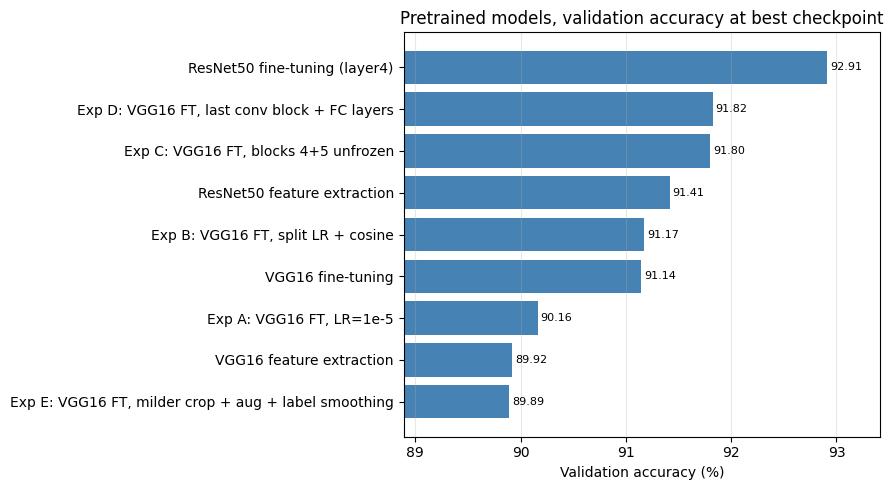

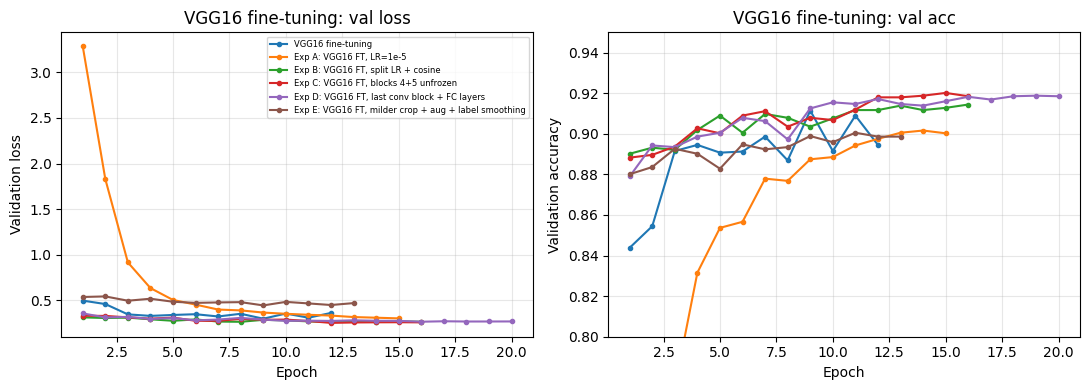

In [18]:
# bar chart (custom CNN left out because it would squash the y-axis, it is way lower)
pretrained = final_table[final_table["Model"] != "Custom CNN"].sort_values("Val acc (%)")
plt.figure(figsize=(9, 5))
plt.barh(pretrained["Model"], pretrained["Val acc (%)"], color="steelblue")
plt.xlim(pretrained["Val acc (%)"].min() - 1, pretrained["Val acc (%)"].max() + 0.5)
for i, v in enumerate(pretrained["Val acc (%)"]):
    plt.text(v + 0.03, i, f"{v:.2f}", va="center", fontsize=8)
plt.xlabel("Validation accuracy (%)")
plt.title("Pretrained models, validation accuracy at best checkpoint")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# validation loss curves for the VGG16 fine-tuning variants
plt.figure(figsize=(11, 4))
vgg_runs = [n for n in results if "VGG16 FT" in n or n == "VGG16 fine-tuning"]
plt.subplot(1, 2, 1)
for n in vgg_runs:
    h = results[n]["history"]
    plt.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], marker=".", label=n)
plt.xlabel("Epoch"); plt.ylabel("Validation loss"); plt.title("VGG16 fine-tuning: val loss")
plt.grid(alpha=0.3); plt.legend(fontsize=6)
plt.subplot(1, 2, 2)
for n in vgg_runs:
    h = results[n]["history"]
    plt.plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], marker=".", label=n)
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy"); plt.title("VGG16 fine-tuning: val acc")
plt.ylim(0.8, 0.95)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Discussion
Accuracy on the Oxford Pet dataset is in the range of 87% to 92% for pretrained articture models and it has a max accurayc of 95% for a custome CNN model with skip onnections


**What the first three models showed**

The custom CNN only got about 17% accuracy. It starts from random weights and only has around 100 images per breed, which isn't enough to learn good features from scratch, especially when many breeds look alike. ResNet50 feature extraction got about 91.7% while training only the last layer (0.08M parameters), so the ImageNet features already do most of the work. VGG16 fine-tuning got about 90.9%, slightly lower even though it trains 7.2M parameters, so training more parameters doesn't automatically give better results. Its validation loss started rising after epoch 11 while training accuracy kept going up, which is a sign of overfitting, and early stopping stopped the run at that point. Training accuracy was lower than validation accuracy in every run, but that isn't a bug. The random crops and dropout make training harder than the clean center-crop used for validation.

**What I tried to improve fine-tuning**

I changed the learning rate (A and B). 1e-5 was stable but too slow, so in B I used a small rate for the pretrained layers, a bigger one for the new layer, and a cosine decay. I unfroze more layers (C) and different layers (D) to give the model more freedom to adapt, though with so little data that could also cause overfitting. I used milder crops, rotation, color jitter and label smoothing (E) to help with preprocessing and overfitting. I used early stopping in every run and raised the epoch limit to 20, because Experiment A was still improving at epoch 15.


**Caveats**

I used the test split as the validation set and picked the best epoch on it, so the accuracies are a bit optimistic. Each run was done once, and 0.3% is only about 11 images, so tiny differences are probably just noise.